# PyTorch CUDA GPU Training

In [159]:
from pathlib import Path
import pickle

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.utils.class_weight import compute_class_weight
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

BASE_DIR = Path.cwd()
DATA_PATH = BASE_DIR / "data" / "cinema_reviews_cleaned_preprocessed.csv"
GLOVE_PATH = BASE_DIR / "embeddings" / "glove.6B.100d.txt"
OUTPUT_DIR = BASE_DIR / "torch_outputs"

MAX_WORDS = 20_000
MAX_LEN = 150
EMBEDDING_DIM = 100
BATCH_SIZE = 32
EPOCHS = 20
PATIENCE = 3
SEED = 42

np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("CUDA is not available. Check that the notebook kernel is TNL Project (.venv-win).")

PyTorch: 2.11.0+cu128
Device: cuda
GPU: NVIDIA GeForce RTX 4060


In [13]:
df_torch = pd.read_csv(DATA_PATH)
texts = df_torch["Preprocessed_Tokens"].fillna("").astype(str)

label_encoder_torch = LabelEncoder()
labels = label_encoder_torch.fit_transform(df_torch["Sentiment"])
print("Classes:", label_encoder_torch.classes_)
print(df_torch["Sentiment"].value_counts())

location_encoder_torch = LabelEncoder()
location_feature = location_encoder_torch.fit_transform(df_torch["Location"]).reshape(-1, 1)

scaler_torch = MinMaxScaler()
numeric_features = scaler_torch.fit_transform(
    df_torch[["Star_Rating", "Preprocessed_Token_Count"]]
)
metadata_torch = np.column_stack([location_feature, numeric_features]).astype(np.float32)

Classes: ['Negative' 'Neutral' 'Positive']
Sentiment
Positive    164
Negative    154
Neutral     120
Name: count, dtype: int64


In [14]:
def tokenize_texts_torch(texts):
    word_counts = {}
    for text in texts:
        for word in str(text).split():
            word_counts[word] = word_counts.get(word, 0) + 1

    most_common = sorted(word_counts.items(), key=lambda item: item[1], reverse=True)
    word_index = {"<PAD>": 0, "<OOV>": 1}
    for word, _ in most_common[: MAX_WORDS - 2]:
        word_index[word] = len(word_index)

    sequences = np.zeros((len(texts), MAX_LEN), dtype=np.int64)
    for row_idx, text in enumerate(texts):
        token_ids = [word_index.get(word, 1) for word in str(text).split()]
        token_ids = token_ids[:MAX_LEN]
        sequences[row_idx, : len(token_ids)] = token_ids

    return sequences, word_index


def load_embedding_matrix_torch(word_index):
    embedding_matrix = np.random.normal(
        loc=0.0,
        scale=0.05,
        size=(len(word_index), EMBEDDING_DIM),
    ).astype(np.float32)
    embedding_matrix[0] = 0.0

    matched_words = 0
    with GLOVE_PATH.open(encoding="utf8") as f:
        for line in f:
            values = line.rstrip().split()
            word = values[0]
            idx = word_index.get(word)
            if idx is None:
                continue
            embedding_matrix[idx] = np.asarray(values[1:], dtype=np.float32)
            matched_words += 1

    print(f"Matched GloVe words: {matched_words}/{len(word_index)}")
    return embedding_matrix

sequences_torch, word_index_torch = tokenize_texts_torch(texts)
embedding_matrix_torch = load_embedding_matrix_torch(word_index_torch)

Matched GloVe words: 1873/2103


In [188]:
indices = np.arange(len(df_torch))
train_idx, test_idx = train_test_split(
    indices,
    test_size=0.2,
    random_state=SEED,
    stratify=labels,
)

x_text_train_torch = torch.tensor(sequences_torch[train_idx], dtype=torch.long)
x_text_test_torch = torch.tensor(sequences_torch[test_idx], dtype=torch.long)
x_meta_train_torch = torch.tensor(metadata_torch[train_idx], dtype=torch.float32)
x_meta_test_torch = torch.tensor(metadata_torch[test_idx], dtype=torch.float32)
y_train_torch = torch.tensor(labels[train_idx], dtype=torch.long)
y_test_torch = torch.tensor(labels[test_idx], dtype=torch.long)

train_loader_torch = DataLoader(
    TensorDataset(x_text_train_torch, x_meta_train_torch, y_train_torch),
    batch_size=BATCH_SIZE,
    shuffle=True,
)
test_loader_torch = DataLoader(
    TensorDataset(x_text_test_torch, x_meta_test_torch, y_test_torch),
    batch_size=BATCH_SIZE,
    shuffle=False,
)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(labels[train_idx]),
    y=labels[train_idx],
)
class_weights_torch = torch.tensor(class_weights, dtype=torch.float32).to(device)
print("Class weights:", class_weights)

Class weights: [0.94850949 1.21527778 0.89058524]


In [189]:
class SentimentBiGRU(nn.Module):
    def __init__(self, embedding_matrix, metadata_dim, num_classes):
        super().__init__()
        self.embedding = nn.Embedding.from_pretrained(
            torch.tensor(embedding_matrix),
            freeze=True,
            padding_idx=0,
        )
        self.gru = nn.GRU(
            input_size=EMBEDDING_DIM,
            hidden_size=128,
            num_layers=2,
            batch_first=True,
            bidirectional=True,
            # dropout=0.3,
            dropout=0.4,
        )
        self.metadata = nn.Sequential(
            nn.Linear(metadata_dim, 16),
            nn.ReLU(),
            nn.Dropout(0.2),
        )
        self.classifier = nn.Sequential(
            nn.Linear(256 + 16, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes),
        )

    def forward(self, text_input, metadata_input):
        embedded = self.embedding(text_input)
        gru_output, _ = self.gru(embedded)
        pooled = torch.max(gru_output, dim=1).values
        meta = self.metadata(metadata_input)
        combined = torch.cat([pooled, meta], dim=1)
        return self.classifier(combined)

model_torch = SentimentBiGRU(
    embedding_matrix=embedding_matrix_torch,
    metadata_dim=metadata_torch.shape[1],
    num_classes=len(label_encoder_torch.classes_),
).to(device)

criterion_torch = nn.CrossEntropyLoss(weight=class_weights_torch)
optimizer_torch = torch.optim.Adam(model_torch.parameters(), lr=1e-3)
# optimizer_torch = torch.optim.Adam(model_torch.parameters(), lr=5e-4)
scheduler_torch = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_torch,
    mode="min",
    factor=0.5,
    patience=2,
)
model_torch

SentimentBiGRU(
  (embedding): Embedding(2103, 100, padding_idx=0)
  (gru): GRU(100, 128, num_layers=2, batch_first=True, dropout=0.4, bidirectional=True)
  (metadata): Sequential(
    (0): Linear(in_features=3, out_features=16, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
  )
  (classifier): Sequential(
    (0): Linear(in_features=272, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=3, bias=True)
  )
)

In [190]:
OUTPUT_DIR.mkdir(exist_ok=True)
best_val_loss = float("inf")
epochs_without_improvement = 0

for epoch in range(1, EPOCHS + 1):
    model_torch.train()
    train_loss = 0.0
    correct = 0
    total = 0

    for text_batch, meta_batch, label_batch in train_loader_torch:
        text_batch = text_batch.to(device)
        meta_batch = meta_batch.to(device)
        label_batch = label_batch.to(device)

        optimizer_torch.zero_grad()
        logits = model_torch(text_batch, meta_batch)
        loss = criterion_torch(logits, label_batch)
        loss.backward()
        optimizer_torch.step()

        train_loss += loss.item() * label_batch.size(0)
        correct += (logits.argmax(dim=1) == label_batch).sum().item()
        total += label_batch.size(0)

    train_loss /= total
    train_acc = correct / total

    model_torch.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for text_batch, meta_batch, label_batch in test_loader_torch:
            text_batch = text_batch.to(device)
            meta_batch = meta_batch.to(device)
            label_batch = label_batch.to(device)

            logits = model_torch(text_batch, meta_batch)
            loss = criterion_torch(logits, label_batch)
            preds = logits.argmax(dim=1)

            val_loss += loss.item() * label_batch.size(0)
            val_correct += (preds == label_batch).sum().item()
            val_total += label_batch.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total
    scheduler_torch.step(val_loss)

    print(
        f"Epoch {epoch:02d} | "
        f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
        f"val_loss={val_loss:.4f} val_acc={val_acc:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_without_improvement = 0
        torch.save(model_torch.state_dict(), OUTPUT_DIR / "test_sentiment_bigru.pt")
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= PATIENCE:
            print("Early stopping.")
            break

Epoch 01 | train_loss=1.0628 train_acc=0.4286 | val_loss=1.0293 val_acc=0.4886
Epoch 02 | train_loss=0.9617 train_acc=0.6000 | val_loss=0.9069 val_acc=0.6136
Epoch 03 | train_loss=0.8423 train_acc=0.6629 | val_loss=0.7962 val_acc=0.7273
Epoch 04 | train_loss=0.7398 train_acc=0.7114 | val_loss=0.7877 val_acc=0.6591
Epoch 05 | train_loss=0.6798 train_acc=0.7371 | val_loss=0.6965 val_acc=0.7273
Epoch 06 | train_loss=0.5712 train_acc=0.8086 | val_loss=0.7047 val_acc=0.7159
Epoch 07 | train_loss=0.5310 train_acc=0.8057 | val_loss=0.6272 val_acc=0.7841
Epoch 08 | train_loss=0.4378 train_acc=0.8343 | val_loss=0.6585 val_acc=0.7727
Epoch 09 | train_loss=0.3460 train_acc=0.8771 | val_loss=0.7415 val_acc=0.7273
Epoch 10 | train_loss=0.3378 train_acc=0.8600 | val_loss=0.9045 val_acc=0.7273
Early stopping.


              precision    recall  f1-score   support

    Negative       0.85      0.94      0.89        31
     Neutral       0.63      0.71      0.67        24
    Positive       0.85      0.70      0.77        33

    accuracy                           0.78        88
   macro avg       0.78      0.78      0.78        88
weighted avg       0.79      0.78      0.78        88



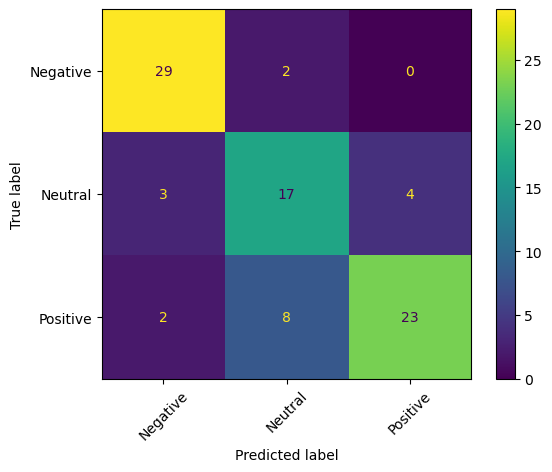

In [191]:
model_torch.load_state_dict(
    torch.load(OUTPUT_DIR / "test_sentiment_bigru.pt", map_location=device)
)
model_torch.eval()

all_preds_torch = []
all_labels_torch = []

with torch.no_grad():
    for text_batch, meta_batch, label_batch in test_loader_torch:
        logits = model_torch(text_batch.to(device), meta_batch.to(device))
        all_preds_torch.extend(logits.argmax(dim=1).cpu().numpy())
        all_labels_torch.extend(label_batch.numpy())

print(
    classification_report(
        all_labels_torch,
        all_preds_torch,
        target_names=label_encoder_torch.classes_,
    )
)

ConfusionMatrixDisplay.from_predictions(
    all_labels_torch,
    all_preds_torch,
    display_labels=label_encoder_torch.classes_,
    xticks_rotation=45,
)
plt.show()

In [183]:
with (OUTPUT_DIR / "word_index.pkl").open("wb") as f:
    pickle.dump(word_index_torch, f)
with (OUTPUT_DIR / "label_encoder.pkl").open("wb") as f:
    pickle.dump(label_encoder_torch, f)
with (OUTPUT_DIR / "location_encoder.pkl").open("wb") as f:
    pickle.dump(location_encoder_torch, f)
with (OUTPUT_DIR / "scaler.pkl").open("wb") as f:
    pickle.dump(scaler_torch, f)

print("Saved PyTorch CUDA model files to:", OUTPUT_DIR)

Saved PyTorch CUDA model files to: c:\Users\User\Desktop\Projects\NLP\torch_outputs
